In [ ]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Audio

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [ ]:
class CNNTransformer(nn.Module):

    def __init__(
        self,
        num_classes=10,
        d_model=128,
        nhead=4,
        num_layers=2,
        dim_feedforward=256,
        dropout=0.2
    ):
        super().__init__()

        self.cnn = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(2)
        )

        self.projection = nn.Linear(
            128 * 16,
            d_model
        )

        self.positional_encoding = nn.Parameter(
            torch.zeros(1, 32, d_model)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, 64),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        x = self.cnn(x)

        x = x.permute(0, 3, 1, 2)

        x = x.reshape(
            x.size(0),
            x.size(1),
            -1
        )

        x = self.projection(x)

        x = x + self.positional_encoding

        x = self.transformer(x)

        x = x.mean(dim=1)

        x = self.classifier(x)

        return x

In [ ]:
# загружаем checkpoint
checkpoint = torch.load(
    "/content/cnn_transformer_final_checkpoint.pt",
    map_location=device
)

model = CNNTransformer(
    num_classes=checkpoint["num_classes"],
    d_model=checkpoint["d_model"],
    nhead=checkpoint["nhead"],
    num_layers=checkpoint["num_layers"],
    dim_feedforward=checkpoint["dim_feedforward"],
    dropout=checkpoint["dropout"]
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)

model.eval()

print("Модель загружена")

Модель загружена


/tmp/ipykernel_1444/3851282681.py:66: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Функция обработки нового WAV

In [ ]:
SAMPLE_RATE = 22050
N_MELS = 128
N_FFT = 2048
HOP_LENGTH = 512

TARGET_HEIGHT = 128
TARGET_WIDTH = 256

In [ ]:
# Функция Mel
def extract_mel_spectrogram(filepath):

    audio, sr = librosa.load(
        filepath,
        sr=SAMPLE_RATE,
        mono=True
    )

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    mel_db = np.clip(
        mel_db,
        -80,
        0
    )

    return mel_db

In [ ]:
# Resize
def resize_spectrogram(spec):

    spec_tensor = torch.tensor(
        spec,
        dtype=torch.float32
    )

    spec_tensor = spec_tensor.unsqueeze(0).unsqueeze(0)

    spec_tensor = F.interpolate(
        spec_tensor,
        size=(TARGET_HEIGHT, TARGET_WIDTH),
        mode='bilinear',
        align_corners=False
    )

    return spec_tensor.squeeze().numpy()

In [ ]:
def normalize_mel(mel):

    mel = np.clip(
        mel,
        -80,
        0
    )

    mel = (mel + 80) / 80

    return mel

In [ ]:
# Mel + Delta + Delta-Delta
def extract_mel_delta_features(filepath):

    mel_db = extract_mel_spectrogram(filepath)

    n_frames = mel_db.shape[1]

    if n_frames >= 9:
        width = 9
    elif n_frames >= 7:
        width = 7
    elif n_frames >= 5:
        width = 5
    elif n_frames >= 3:
        width = 3
    else:
        width = None

    if width is not None:

        delta = librosa.feature.delta(
            mel_db,
            order=1,
            width=width,
            mode='nearest'
        )

        delta_delta = librosa.feature.delta(
            mel_db,
            order=2,
            width=width,
            mode='nearest'
        )

    else:

        delta = np.zeros_like(mel_db)

        delta_delta = np.zeros_like(mel_db)

    # Resize
    mel_db = resize_spectrogram(mel_db)

    delta = resize_spectrogram(delta)

    delta_delta = resize_spectrogram(
        delta_delta
    )

    # Normalize Mel
    mel_db = normalize_mel(mel_db)

    # Normalize Delta
    delta_min = delta.min()
    delta_max = delta.max()

    delta = (
        delta - delta_min
    ) / (
        delta_max - delta_min + 1e-8
    )

    # Normalize Delta-Delta
    delta_delta_min = delta_delta.min()
    delta_delta_max = delta_delta.max()

    delta_delta = (
        delta_delta - delta_delta_min
    ) / (
        delta_delta_max -
        delta_delta_min +
        1e-8
    )

    # 3 канала
    features = np.stack(
        [
            mel_db,
            delta,
            delta_delta
        ],
        axis=0
    )

    return features.astype(
        np.float32
    )

Функция предсказания

In [ ]:
class_names = [
    'air_conditioner',
    'car_horn',
    'children_playing',
    'dog_bark',
    'drilling',
    'engine_idling',
    'gun_shot',
    'jackhammer',
    'siren',
    'street_music'
]

In [ ]:
def predict_wav(filepath):

    # Получаем признаки
    features = extract_mel_delta_features(filepath)

    # Добавляем batch dimension
    x = torch.tensor(features, dtype=torch.float32).unsqueeze(0)

    x = x.to(device)

    # Предсказание
    model.eval()

    with torch.no_grad():

        outputs = model(x)

        probabilities = torch.softmax(outputs, dim=1)

        confidence, predicted_class = torch.max(probabilities, dim=1)

    predicted_index = predicted_class.item()

    predicted_name = class_names[predicted_index]

    confidence = confidence.item()

    probabilities = probabilities[0].cpu().numpy()

    return (
        predicted_name,
        predicted_index,
        confidence,
        probabilities
    )

Предсказываем новый WAV

In [ ]:
wav_path = "/content/Музыка Voice.wav"

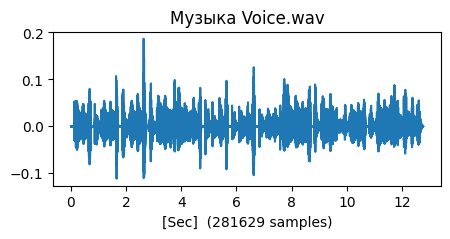

Sample rate: 22050
Количество отсчётов: 281629


In [ ]:
# Загружаем аудио
audio, sr = librosa.load(wav_path)
plt.figure(figsize=(5,2))
plt.plot(np.linspace(0,len(audio)/sr,len(audio)),audio)
plt.title(f"{wav_path[9:]}")
plt.xlabel(f"[Sec]  ({len(audio)} samples)")
plt.show()
display(Audio(data=audio, rate=sr))
print('Sample rate:', sr)
print('Количество отсчётов:', len(audio))

In [ ]:
predicted_name, predicted_index, confidence, probabilities = predict_wav(
    wav_path
)

In [ ]:
print("Предсказанный класс:", predicted_name)
print("Номер класса:", predicted_index)
print(f"Уверенность модели: {confidence:.2%}")

Предсказанный класс: street_music
Номер класса: 9
Уверенность модели: 85.09%


In [ ]:
# вероятности всех классов
print("\nВероятности классов:")

for class_name, probability in zip(
    class_names,
    probabilities
):
    print(
        f"{class_name:20s} : {probability:.2%}"
    )


Вероятности классов:
air_conditioner      : 0.01%
car_horn             : 0.02%
children_playing     : 0.02%
dog_bark             : 0.00%
drilling             : 0.01%
engine_idling        : 14.10%
gun_shot             : 0.00%
jackhammer           : 0.76%
siren                : 0.00%
street_music         : 85.09%
